# 3. Visualization

Draw the `result/images/` style figures (ACF, correlation heatmap, cumulative-return histogram) per model and save them,
then validate the dataset by cross-checking it against yfinance.

- Models: ours (=`baseline`, C2C/w10), QuantGAN, TailGAN, Diffusion-TS.
- Saved to `result/images/{acf,correlation,histogram}/` (transparent-background PNG), same as before.
- Data source: all six assets come from **CRSP** (`data/indices.csv`). This notebook cross-checks the CRSP prices
  against public **yfinance** data as an independent validation (index/commodity series align closely; JPM differs slightly).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.utils import *
from utils.file_manager import LOCAL_BASE_DIRECTORY, quantDiffusionPath

file_manager = quantDiffusionPath()
SEQ_LEN = 256
SD = os.path.join(LOCAL_BASE_DIRECTORY, "result", "statistics", "synthetic_data")
feature_names = ["DJI", "NASDAQ", "JPM", "HSI", "GOLD", "WTI_OIL"]

# model: tag (folder) -> display name
MODELS = {
    "baseline": "QuantDiffusion (ours)",
    "quantgan": "QuantGAN",
    "tailgan": "TailGAN",
    "diffusionTS": "Diffusion-TS",
}

# real reference = test split of indices.csv, 6d (same as the benchmark)
df = pd.read_csv("./data/indices.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")
df.set_index("Date", inplace=True)
df = df.apply(pd.to_numeric).astype(float)
df_log_returns = np.log1p(df.pct_change()).dropna()
train_size = int(0.7 * len(df_log_returns))
test_raw = df_log_returns.iloc[train_size:, :]
real_data = np.transpose(rolling_window(test_raw.values, SEQ_LEN), (0, 2, 1))  # (B,6,T)
print("real_data (test 6d):", real_data.shape)

# load each model's synthetic data (set 0)
fakes = {}
for tag in MODELS:
    p = os.path.join(SD, tag, "0.npy")
    if os.path.exists(p):
        fakes[tag] = np.load(p)
    else:
        print(f"  (skip {tag}: {p} not found)")
print("loaded fakes:", {t: v.shape for t, v in fakes.items()})

real_data (test 6d): (1538, 6, 256)
loaded fakes: {'baseline': (2000, 6, 256), 'quantgan': (2000, 6, 256), 'tailgan': (2000, 6, 256), 'diffusionTS': (2000, 6, 256)}


C:\Users\Juhwankim\miniconda3\envs\research\lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in log1p
  result = func(self.values, **kwargs)


## 3-1. Paper figures

The four generated figures of the paper, one cell each, saved straight into `result/images/figures/`. The architecture figure is authored in draw.io and is not built here.

In [2]:
# The four generated figures of the paper are built by
# utils/make_paper_figures.py, which resolves its own paths and writes straight
# into result/images, the directory the paper's \graphicspath points at. The
# cells below call those builders instead of re-plotting, so the figure in the pdf
# and the figure here cannot drift apart. fig5, the architecture, is a draw.io
# export and is not generated here.
#
# Note: importing the builders switches matplotlib to the Agg backend.
from IPython.display import Image, display

import utils.make_paper_figures as pf

IMG = pf.OUT
print("output ->", IMG)
print(f"widths for acmart sigconf: {pf.COL} in one column, {pf.FULL} in two, "
      f"{pf.DPI} dpi")


output -> C:\Users\Juhwankim\Documents\Github\quantDiffusion\result\images
widths for acmart sigconf: 3.33 in one column, 7.0 in two, 400 dpi


C:\Users\Juhwankim\miniconda3\envs\research\lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in log1p
  result = func(self.values, **kwargs)


  wrote result\images\fig1_stylized_facts.png


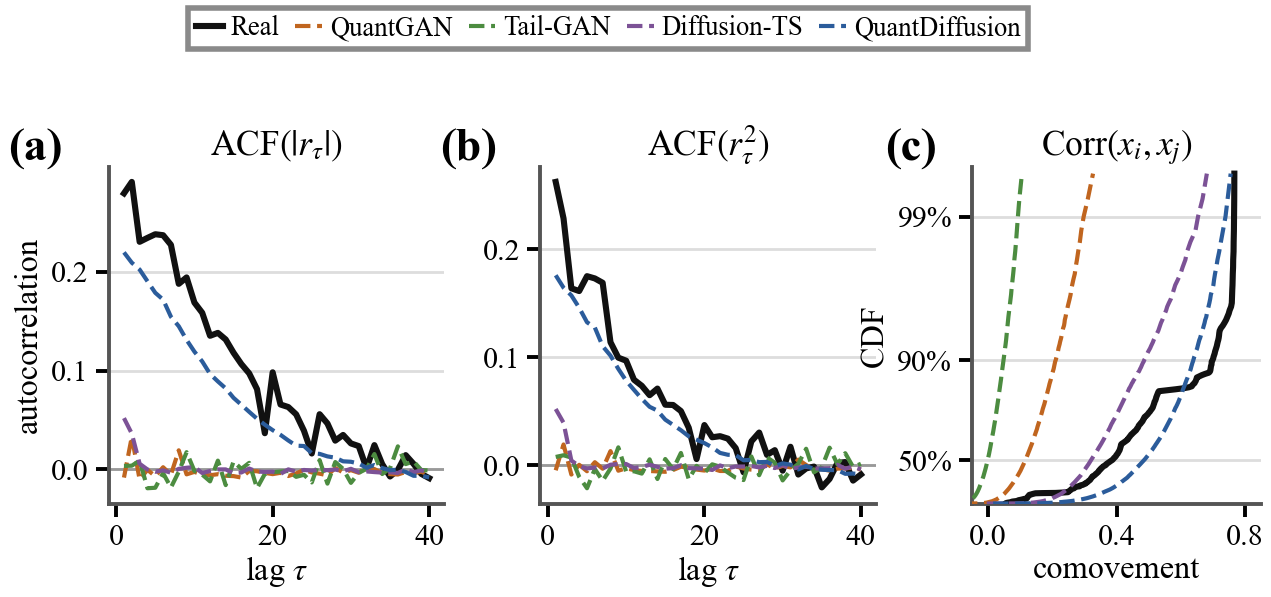

In [3]:
# fig1  stylized facts
#   (a) ACF of |r|   (b) ACF of r^2
#   (c) cross asset comovement of x_t = log RV_t, one value per 256 day scenario,
#       drawn against how rare the scenario is, so the right hand edge gives each
#       model's ceiling. The Vol CCF(tau=0) row of the fidelity table scores the
#       same correlation matrix entry by entry; this panel keeps the per scenario
#       spread that the row averages away. Every scenario is used.
pf.fig1()
display(Image(os.path.join(IMG, "fig1_stylized_facts.png"), width=720))


C:\Users\Juhwankim\miniconda3\envs\research\lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in log1p
  result = func(self.values, **kwargs)


  wrote result\images\fig2_distribution.png


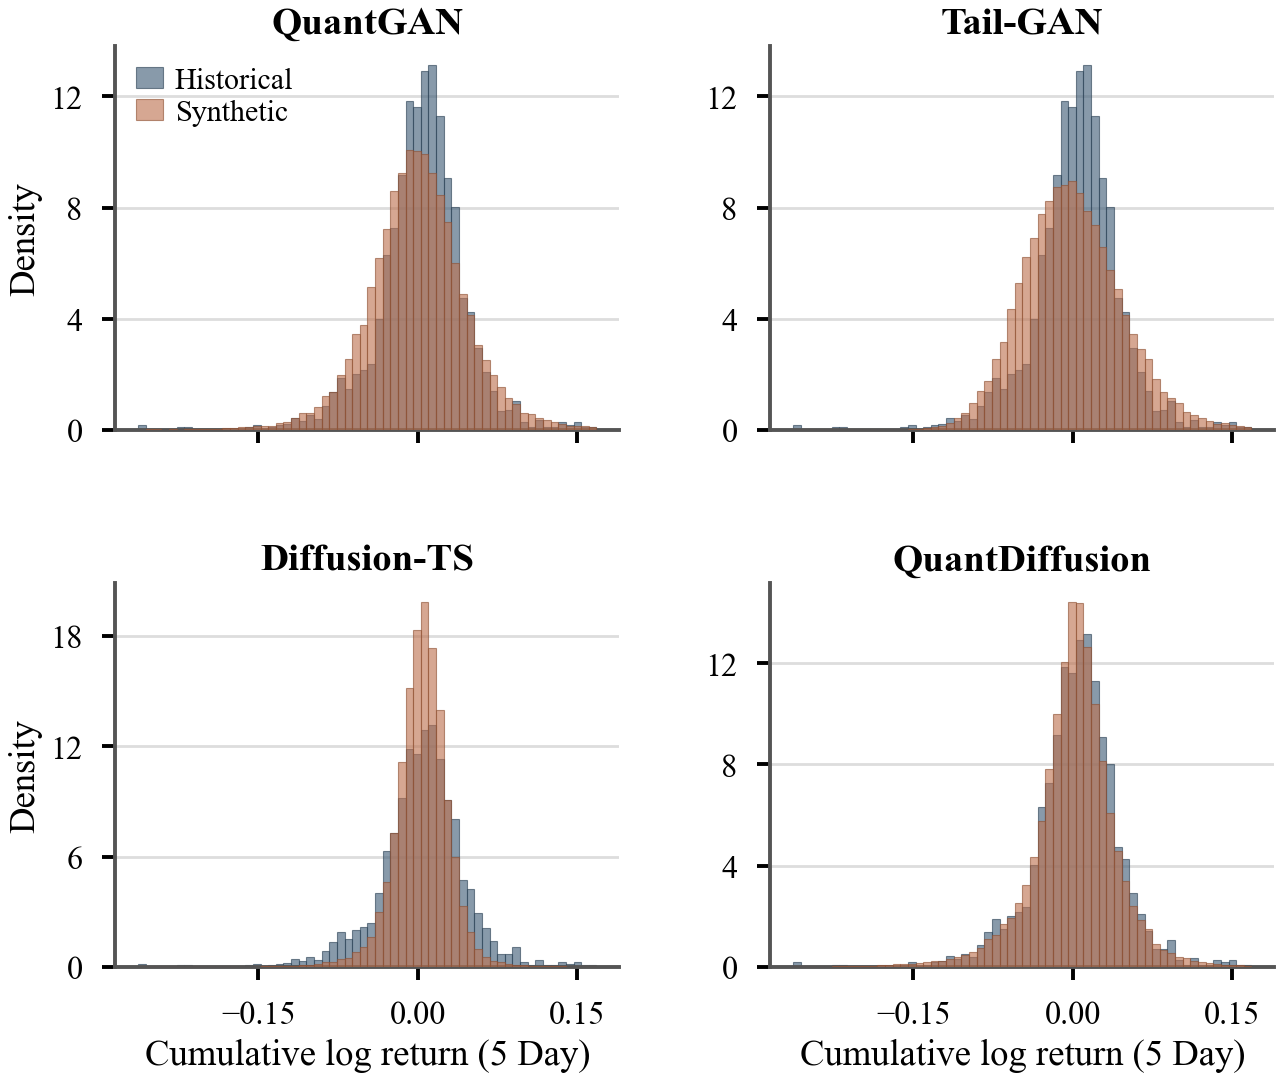

In [4]:
# fig2  five day cumulative log return distributions for JP Morgan,
#       historical against each generator, on a common set of bins
pf.fig2()
display(Image(os.path.join(IMG, "fig2_distribution.png"), width=720))


  wrote result\images\fig3_risk_radars.png


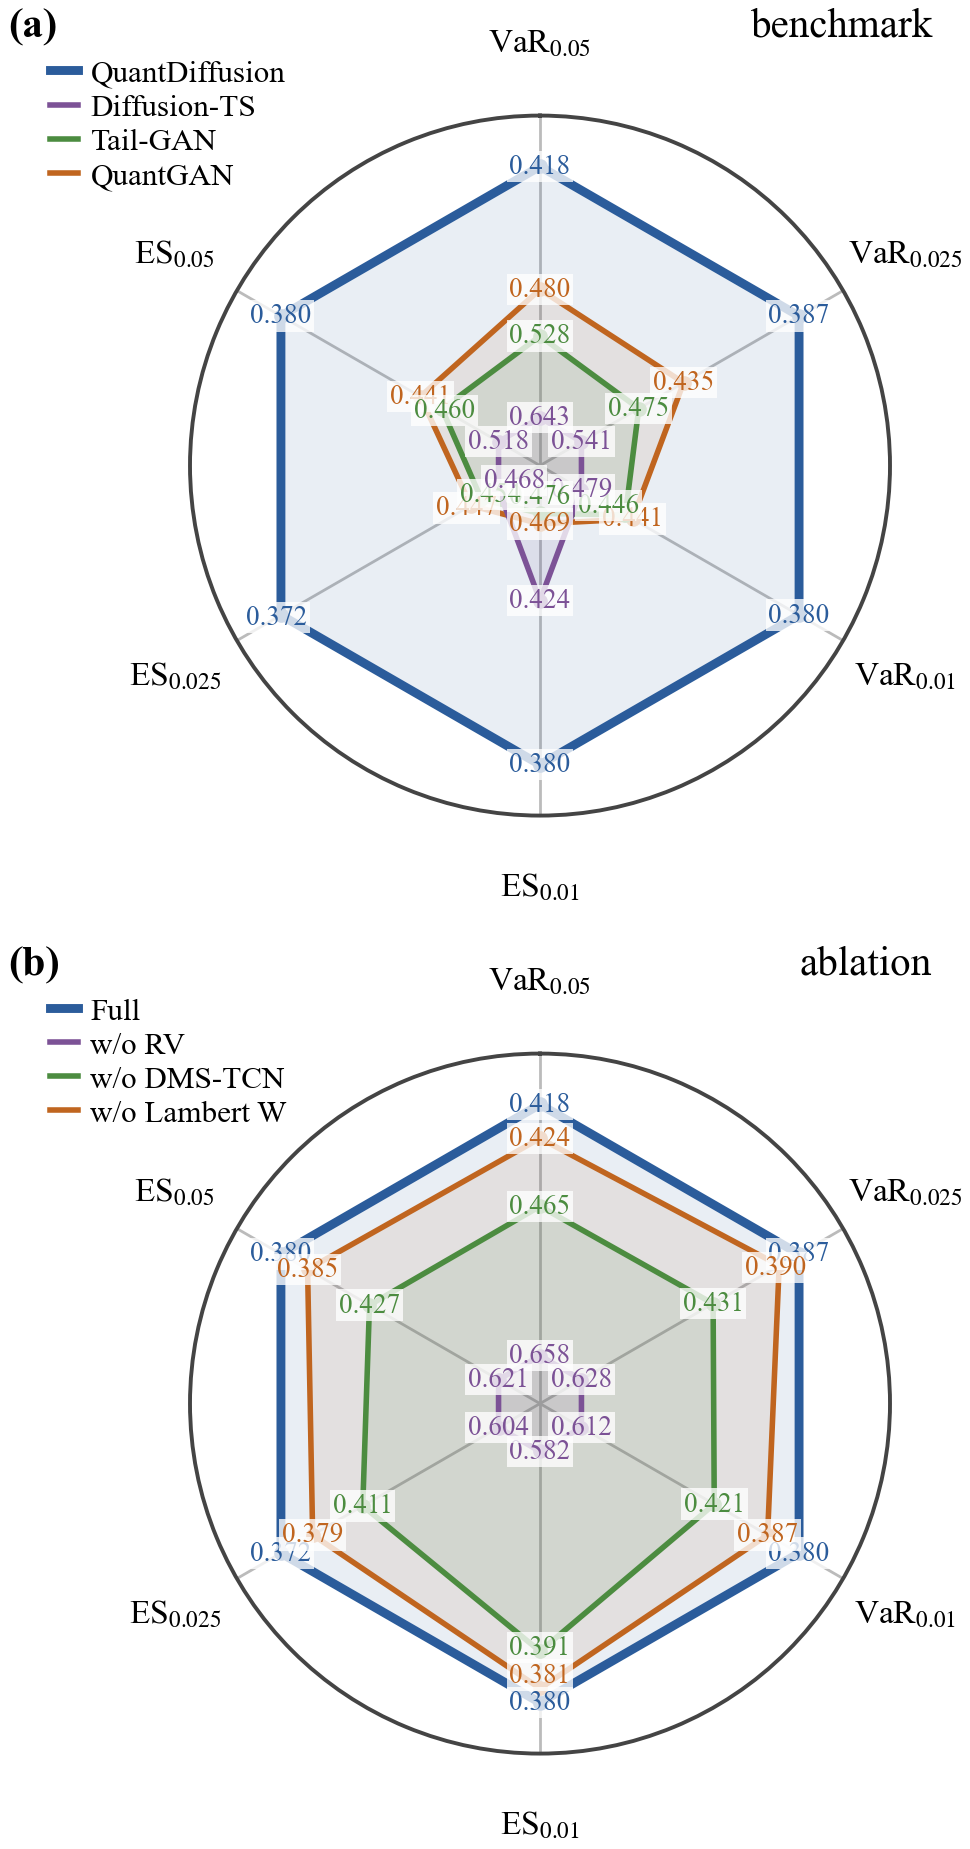

In [5]:
# fig3  relative error of portfolio VaR and ES
#   (a) against the baselines   (b) across the ablation variants
# Read from result/statistics/benchmark__tailgan_vares.csv and
# ablation__tailgan_vares.csv, so rerun notebooks 1 and 2 first if the samples
# changed.
pf.fig3()
display(Image(os.path.join(IMG, "fig3_risk_radars.png"), width=430))


  h=20: 5 baskets to compute


  h=40: 5 baskets to compute


  h=64: 5 baskets to compute


  h=64: 4 baskets to compute


  h=96: 5 baskets to compute


...

  h=160: 5 baskets to compute


  h=160: 2 baskets to compute


  h=200: 5 baskets to compute


  h=200: 2 baskets to compute


  wrote result\images\fig4_risk_horizon.png


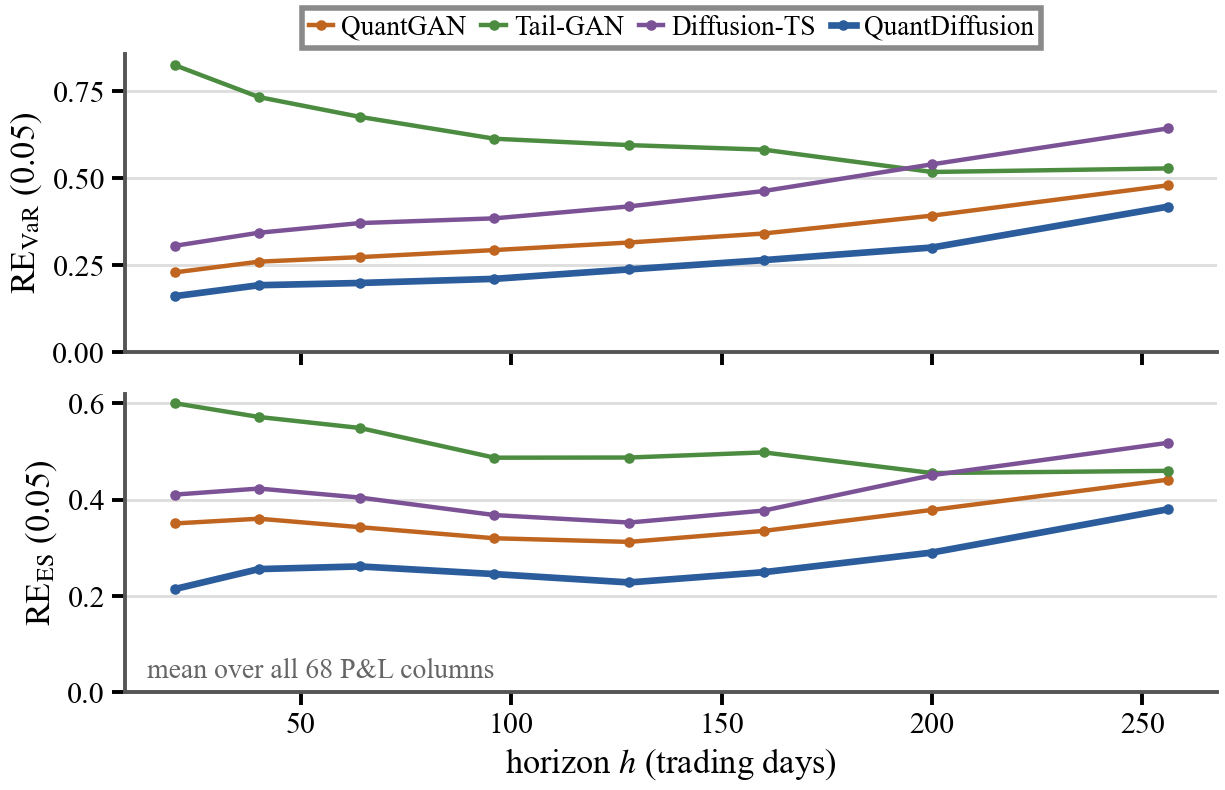

In [6]:
# fig4  VaR and ES error at every horizon from 20 to 255 trading days
#
# This one calls TailGAN's Compute_PNL, which corrupts the heap on CPU: the P&L
# values come out correct, then the process dies at whatever allocates next. Each
# horizon is therefore computed in a subprocess that writes its result and leaves
# through os._exit, cached under result/images/pnl_cache/. The first run
# takes a couple of minutes, later runs are instant. Delete pnl_cache to force a
# recompute after the synthetic samples change.
import os as _os

_os.environ["CUDA_VISIBLE_DEVICES"] = "-1"      # keep it off a busy GPU
pf.fig4()
display(Image(os.path.join(IMG, "fig4_risk_horizon.png"), width=720))


## 3-2. CRSP data vs yfinance (cross-check)
The dataset (`indices.csv`) is sourced from **CRSP**. Here we validate it against public **yfinance** data:
close agreement confirms the CRSP series, and small residual differences reflect source/adjustment conventions
(JPM in particular).

In [7]:
import yfinance as yf

# CRSP column -> yfinance ticker used only as an external cross-check reference
TICKER_MAP = {"DJI": "^DJI", "NASDAQ": "^IXIC", "JPM": "JPM",
              "HSI": "^HSI", "GOLD": "GC=F", "WTI_OIL": "CL=F"}
SOURCE = {k: "CRSP" for k in TICKER_MAP}   # all six assets are from CRSP

start = df.index.min().strftime("%Y-%m-%d")
end = (df.index.max() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
raw = yf.download(list(TICKER_MAP.values()), start=start, end=end,
                  auto_adjust=False, progress=False)
close = raw["Close"] if isinstance(raw.columns, pd.MultiIndex) else raw
inv = {v: k for k, v in TICKER_MAP.items()}
yf_close = close.rename(columns=inv)[list(TICKER_MAP.keys())]

# compare CRSP (indices.csv) against yfinance on common dates
rows = []
fig, axs = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axs.ravel(), feature_names):
    a = df[col].dropna()               # CRSP
    b = yf_close[col].dropna()         # yfinance reference
    common = a.index.intersection(b.index)
    a2, b2 = a.loc[common], b.loc[common]
    corr = a2.corr(b2)
    rel = np.abs(a2 - b2) / (np.abs(a2) + 1e-8)
    rows.append({"asset": col, "source": SOURCE[col], "n_common": len(common),
                 "corr": round(corr, 6), "max_rel_diff": round(float(rel.max()), 5),
                 "median_rel_diff": round(float(rel.median()), 6)})
    ax.plot(a2.index, a2.values, label="CRSP (indices.csv)", lw=1.2)
    ax.plot(b2.index, b2.values, label="yfinance", lw=0.8, ls="--")
    ax.set_title(f"{col}  corr={corr:.5f}")
    ax.legend(fontsize=8)
fig.suptitle("CRSP dataset (indices.csv) vs yfinance cross-check", y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(file_manager.get_image_path(), "yfinance_match.png"),
            dpi=150, bbox_inches="tight")
plt.show()

match = pd.DataFrame(rows).set_index("asset")
print(match.to_string())
print("\nNote: all six assets are sourced from CRSP; yfinance is used only as an external cross-check.")
print("      Index/commodity series match yfinance closely; JPM shows a minor difference (source/adjustment conventions).")

        source  n_common  corr  max_rel_diff  median_rel_diff
asset                                                        
DJI       CRSP      5979   1.0       0.00000              0.0
NASDAQ    CRSP      5979   1.0       0.00000              0.0
JPM       CRSP      5979   1.0       0.01103              0.0
HSI       CRSP      5979   1.0       0.00000              0.0
GOLD      CRSP      5979   1.0       0.00000              0.0
WTI_OIL   CRSP      5979   1.0       0.00000              0.0

Note: all six assets are sourced from CRSP; yfinance is used only as an external cross-check.
      Index/commodity series match yfinance closely; JPM shows a minor difference (source/adjustment conventions).


C:\Users\Juhwankim\AppData\Local\Temp\ipykernel_38520\3032225094.py:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
